In [2]:
import pandas as pd

df = pd.read_csv("../data/datalab_export_2026-11-03 21_15_44.csv")
df.head()

,index,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850,United Kingdom
1,1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850,United Kingdom
2,2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850,United Kingdom
3,3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850,United Kingdom
4,4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850,United Kingdom


In [3]:
df.shape

(100, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   index        100 non-null    int64  
 1   InvoiceNo    100 non-null    int64  
 2   StockCode    100 non-null    str    
 3   Description  100 non-null    str    
 4   Quantity     100 non-null    int64  
 5   InvoiceDate  100 non-null    str    
 6   UnitPrice    100 non-null    float64
 7   CustomerID   100 non-null    int64  
 8   Country      100 non-null    str    
dtypes: float64(1), int64(4), str(4)
memory usage: 7.2 KB


In [5]:
df.describe()

,index,InvoiceNo,Quantity,UnitPrice,CustomerID
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,49.500000,536371.870000,13.100000,3.276400,15417.710000
std,29.011492,4.041839,16.887925,2.611142,2319.990749
min,0.000000,536365.000000,2.000000,0.420000,12583.000000
25%,24.750000,536368.750000,6.000000,1.680000,13047.000000
50%,49.500000,536373.000000,6.000000,2.650000,14688.000000
75%,74.250000,536375.000000,13.500000,4.250000,17850.000000
max,99.000000,536378.000000,120.000000,18.000000,17850.000000


In [6]:
df.isna().sum()

index          0
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%y %H:%M")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   index        100 non-null    int64         
 1   InvoiceNo    100 non-null    int64         
 2   StockCode    100 non-null    str           
 3   Description  100 non-null    str           
 4   Quantity     100 non-null    int64         
 5   InvoiceDate  100 non-null    datetime64[us]
 6   UnitPrice    100 non-null    float64       
 7   CustomerID   100 non-null    int64         
 8   Country      100 non-null    str           
dtypes: datetime64[us](1), float64(1), int64(4), str(3)
memory usage: 7.2 KB


In [9]:
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
df[["Quantity", "UnitPrice", "TotalPrice"]].head()

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [10]:
print("CA total :", round(df["TotalPrice"].sum(), 2))
print("Nombre de factures :", df["InvoiceNo"].nunique())
print("Nombre de clients :", df["CustomerID"].nunique())
print("Panier moyen :", round(df.groupby("InvoiceNo")["TotalPrice"].sum().mean(), 2))

CA total : 3122.93
Nombre de factures : 14
Nombre de clients : 7
Panier moyen : 223.07


In [11]:
ca_pays = df.groupby("Country")["TotalPrice"].sum().sort_values(ascending=False)
ca_pays

Country
United Kingdom    2267.07
France             855.86
Name: TotalPrice, dtype: float64

In [12]:
ca_client = df.groupby("CustomerID").agg(
    ca=("TotalPrice", "sum"),
    nb_factures=("InvoiceNo", "nunique")
).sort_values("ca", ascending=False)
ca_client

,ca,nb_factures
CustomerID,,
12583,855.86,1
17850,725.44,6
13047,366.63,3
15100,350.40,1
15291,328.80,1
14688,291.80,1
13748,204.00,1


In [13]:
top_produits = df.groupby("Description")["TotalPrice"].sum().sort_values(ascending=False).head(5)
top_produits

Description
VICTORIAN SEWING BOX LARGE           350.4
PAPER CHAIN KIT 50'S CHRISTMAS       204.0
HOT WATER BOTTLE TEA AND SYMPATHY    165.6
RED HANGING HEART T-LIGHT HOLDER     163.2
ALARM CLOCK BAKELIKE RED              90.0
Name: TotalPrice, dtype: float64

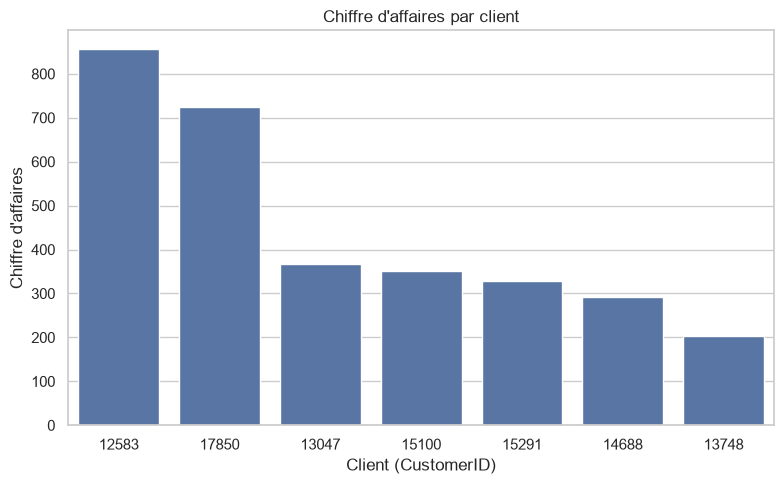

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.barplot(x=ca_client.index.astype(str), y=ca_client["ca"], color="#4C72B0")
plt.title("Chiffre d'affaires par client")
plt.xlabel("Client (CustomerID)")
plt.ylabel("Chiffre d'affaires")
plt.tight_layout()
plt.savefig("../images/ca_par_client.png", dpi=150)
plt.show()